<a href="https://colab.research.google.com/github/Dayveedstartsprogramming/Nuclear-morphometrics/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
mkdir nuclear-morphometrics && cd nuclear-morphometrics
python -m venv venv
source venv/bin/activate          # Windows: venv\Scripts\activate
pip install numpy pandas matplotlib seaborn scipy scikit-learn jupyter
pip freeze > requirements.txt
jupyter notebook


SyntaxError: invalid syntax (793838501.py, line 1)

In [4]:
  import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
COLORS = {"benign": "#3b8ea5", "malignant": "#d1495b"}

In [5]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
features = list(data.feature_names)

# scikit-learn codes 0 = malignant, 1 = benign, so we relabel to avoid mistakes
df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})

print("Shape (rows, columns):", df.shape)
print(df["diagnosis"].value_counts())
print("Missing values:", df[features].isna().sum().sum())
df.head()

Shape (rows, columns): (569, 32)
diagnosis
benign       357
malignant    212
Name: count, dtype: int64
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


In [6]:
for i, f in enumerate(features, 1):
    print(i, f)

1 mean radius
2 mean texture
3 mean perimeter
4 mean area
5 mean smoothness
6 mean compactness
7 mean concavity
8 mean concave points
9 mean symmetry
10 mean fractal dimension
11 radius error
12 texture error
13 perimeter error
14 area error
15 smoothness error
16 compactness error
17 concavity error
18 concave points error
19 symmetry error
20 fractal dimension error
21 worst radius
22 worst texture
23 worst perimeter
24 worst area
25 worst smoothness
26 worst compactness
27 worst concavity
28 worst concave points
29 worst symmetry
30 worst fractal dimension


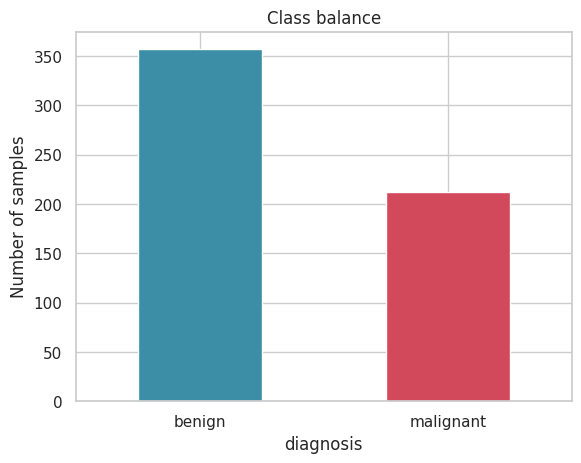

In [7]:
df["diagnosis"].value_counts().plot(kind="bar", color=[COLORS["benign"], COLORS["malignant"]])
plt.ylabel("Number of samples")
plt.title("Class balance")
plt.xticks(rotation=0)
plt.show()

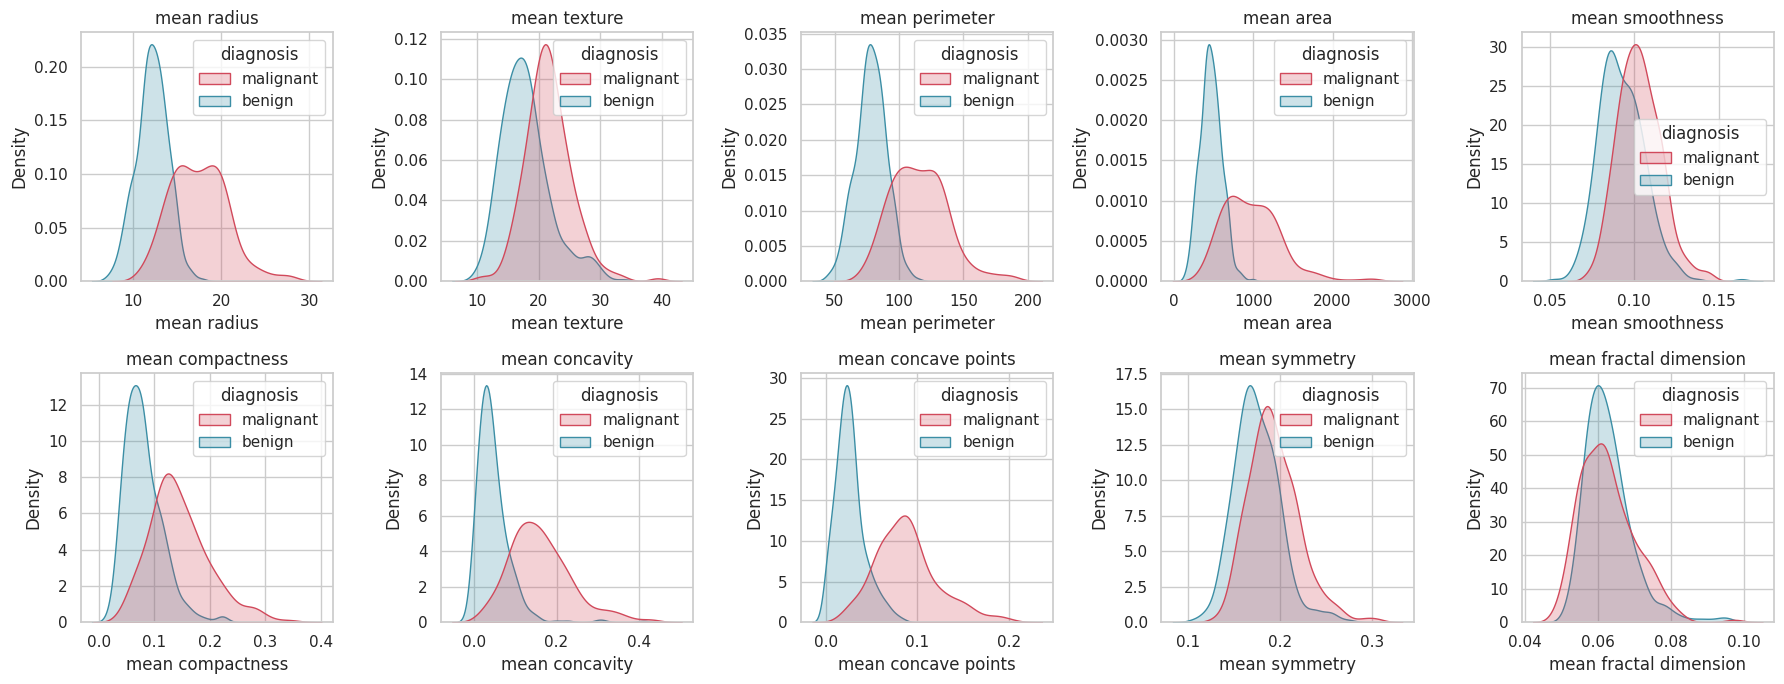

In [8]:
mean_feats = [f for f in features if f.startswith("mean ")]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, f in zip(axes.ravel(), mean_feats):
    sns.kdeplot(data=df, x=f, hue="diagnosis", fill=True, common_norm=False,
                palette=COLORS, ax=ax)
    ax.set_title(f)
plt.tight_layout()
plt.show()

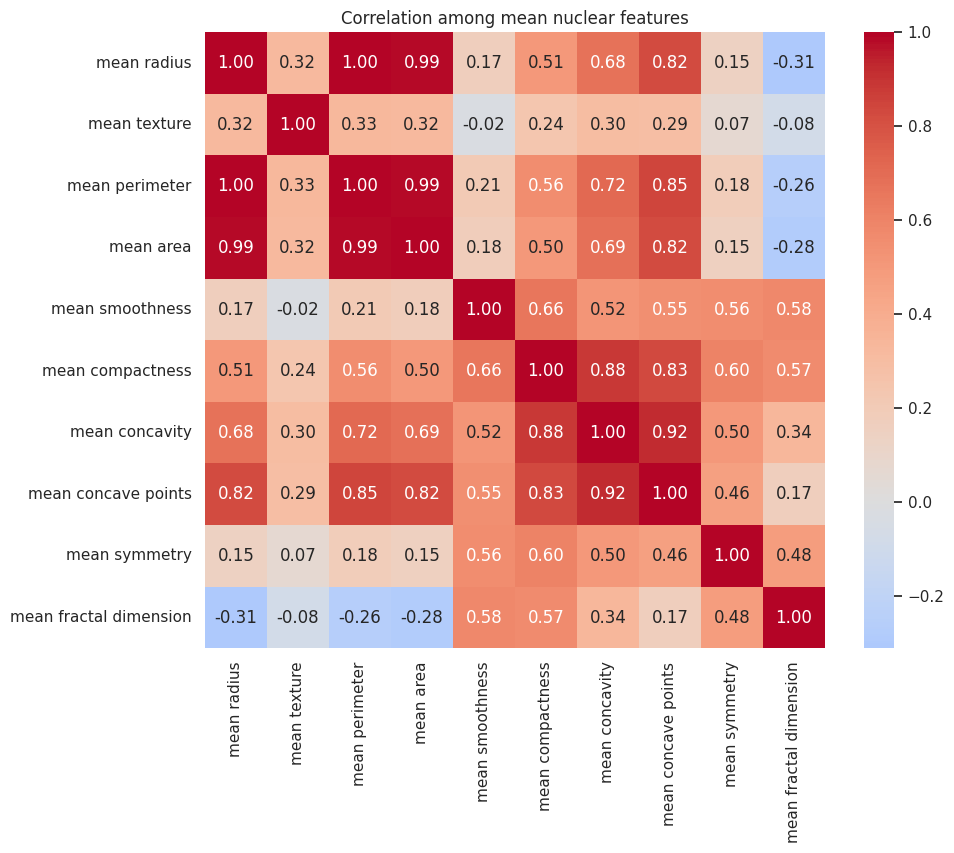

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[mean_feats].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation among mean nuclear features")
plt.show()

In [10]:
# Scale first: area is in the hundreds, smoothness is ~0.1.
# Without scaling, PCA would just follow whichever feature has the biggest numbers.
X_scaled = StandardScaler().fit_transform(df[features])

pca = PCA()
pcs = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_

print("Variance explained by first 5 PCs:", evr[:5].round(3))
print("Cumulative (first 2):", evr[:2].sum().round(3))
print("Cumulative (first 5):", evr[:5].sum().round(3))

Variance explained by first 5 PCs: [0.443 0.19  0.094 0.066 0.055]
Cumulative (first 2): 0.632
Cumulative (first 5): 0.847


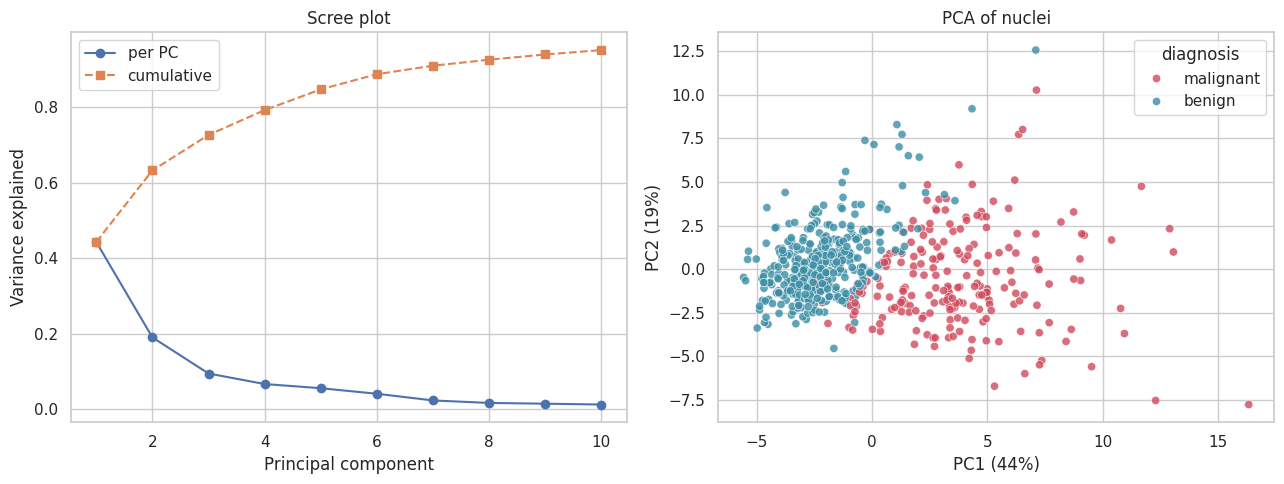

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].plot(range(1, 11), evr[:10], "o-", label="per PC")
ax[0].plot(range(1, 11), np.cumsum(evr[:10]), "s--", label="cumulative")
ax[0].set(xlabel="Principal component", ylabel="Variance explained", title="Scree plot")
ax[0].legend()

sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["diagnosis"], palette=COLORS,
                alpha=0.8, ax=ax[1])
ax[1].set(xlabel=f"PC1 ({evr[0]:.0%})", ylabel=f"PC2 ({evr[1]:.0%})", title="PCA of nuclei")
plt.tight_layout()
plt.show()

In [12]:
loadings = pd.Series(pca.components_[0], index=features)
loadings.sort_values(key=abs, ascending=False).head(10).round(3)

,0
mean concave points,0.261
mean concavity,0.258
worst concave points,0.251
mean compactness,0.239
worst perimeter,0.237
worst concavity,0.229
worst radius,0.228
mean perimeter,0.228
worst area,0.225
mean area,0.221


In [13]:
mal = df[df.diagnosis == "malignant"]
ben = df[df.diagnosis == "benign"]

rows = []
for f in features:
    u, p = stats.mannwhitneyu(mal[f], ben[f], alternative="two-sided")
    effect = 2 * u / (len(mal) * len(ben)) - 1   # rank-biserial correlation, -1 to 1
    rows.append((f, mal[f].median(), ben[f].median(), p, effect))

res = pd.DataFrame(rows, columns=["feature", "median_malignant", "median_benign", "p", "effect_size"])
res.head()

,feature,median_malignant,median_benign,p,effect_size
0,mean radius,17.3250,12.20000,2.692943e-68,0.875033
1,mean texture,21.4600,17.39000,3.428627e-28,0.551649
2,mean perimeter,114.2000,78.18000,3.553870e-71,0.893795
3,mean area,932.0000,458.40000,1.539780e-68,0.876632
4,mean smoothness,0.1022,0.09076,7.793007e-19,0.444083


In [14]:
def bh_fdr(p):
    """Benjamini-Hochberg adjusted p-values (q-values)."""
    p = np.asarray(p)
    n = len(p)
    order = np.argsort(p)                              # sort p-values smallest to largest
    adj = p[order] * n / (np.arange(n) + 1)            # scale each by n / rank
    adj = np.minimum.accumulate(adj[::-1])[::-1]       # q-values can't decrease with rank
    out = np.empty(n)
    out[order] = np.minimum(adj, 1)                    # put back in original order, cap at 1
    return out

res["q_value"] = bh_fdr(res["p"])
res = res.sort_values("effect_size", key=abs, ascending=False).reset_index(drop=True)
res.head(10).round(4)

,feature,median_malignant,median_benign,p,effect_size,q_value
0,worst perimeter,138.0000,86.9200,0.0,0.9509,0.0
1,worst radius,20.5900,13.3500,0.0,0.9409,0.0
2,worst area,1303.0000,547.4000,0.0,0.9397,0.0
3,worst concave points,0.1820,0.0743,0.0,0.9334,0.0
4,mean concave points,0.0863,0.0234,0.0,0.9289,0.0
5,mean perimeter,114.2000,78.1800,0.0,0.8938,0.0
6,mean area,932.0000,458.4000,0.0,0.8766,0.0
7,mean concavity,0.1513,0.0371,0.0,0.8757,0.0
8,mean radius,17.3250,12.2000,0.0,0.8750,0.0
9,area error,58.4550,19.6300,0.0,0.8528,0.0


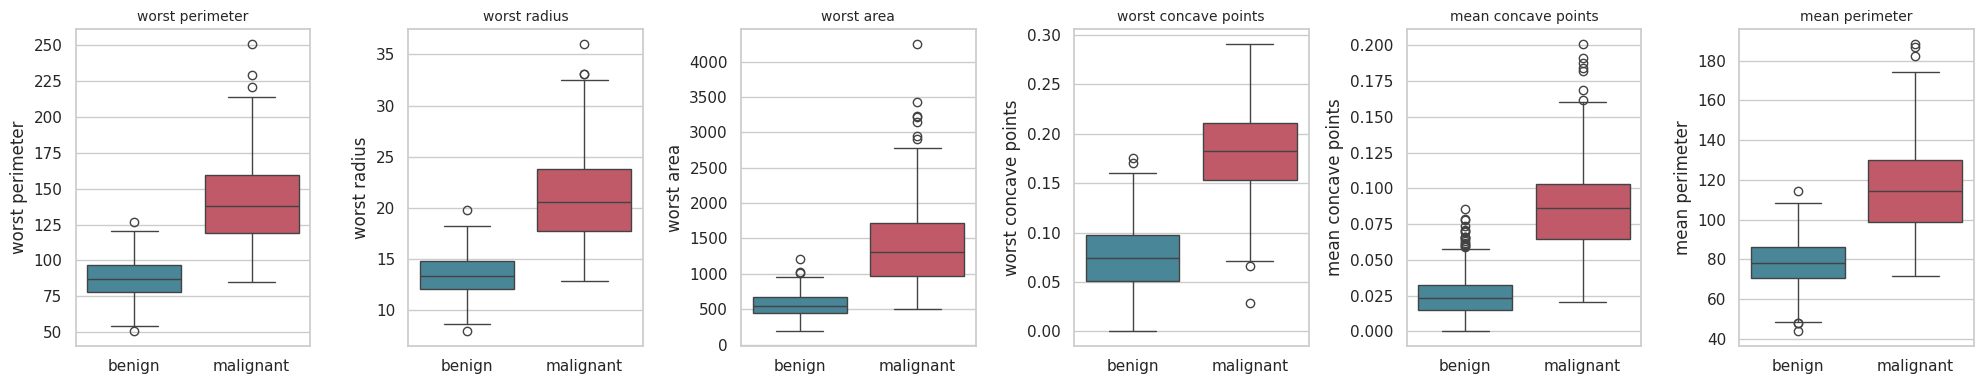

In [15]:
top6 = res.head(6)["feature"].tolist()

fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, f in zip(axes, top6):
    sns.boxplot(data=df, x="diagnosis", y=f, hue="diagnosis", order=["benign", "malignant"],
                palette=COLORS, legend=False, ax=ax)
    ax.set_xlabel("")
    ax.set_title(f, fontsize=10)
plt.tight_layout()
plt.show()

In [16]:
X = df[features]
y = (df["diagnosis"] == "malignant").astype(int)   # 1 = malignant

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print("Train:", X_tr.shape, "Test:", X_te.shape)
print("Malignant fraction, train:", y_tr.mean().round(3), "test:", y_te.mean().round(3))

Train: (426, 30) Test: (143, 30)
Malignant fraction, train: 0.373 test: 0.371


===== Logistic regression =====
5-fold CV AUC (train only): 0.991 +/- 0.009
Test AUC: 0.996
              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        90
   malignant       0.98      0.92      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143



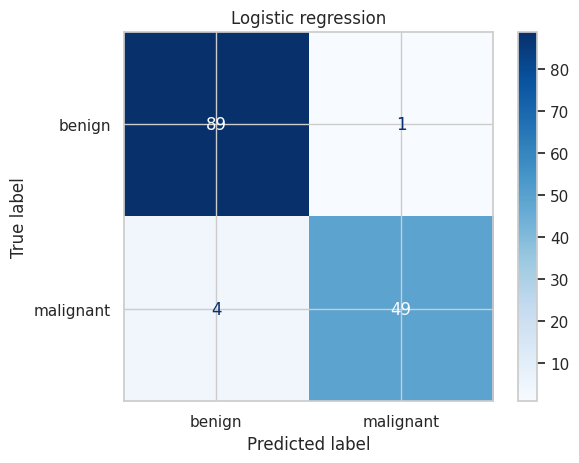

===== Random forest =====
5-fold CV AUC (train only): 0.988 +/- 0.008
Test AUC: 0.995
              precision    recall  f1-score   support

      benign       0.95      1.00      0.97        90
   malignant       1.00      0.91      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.95      0.96       143
weighted avg       0.97      0.97      0.96       143



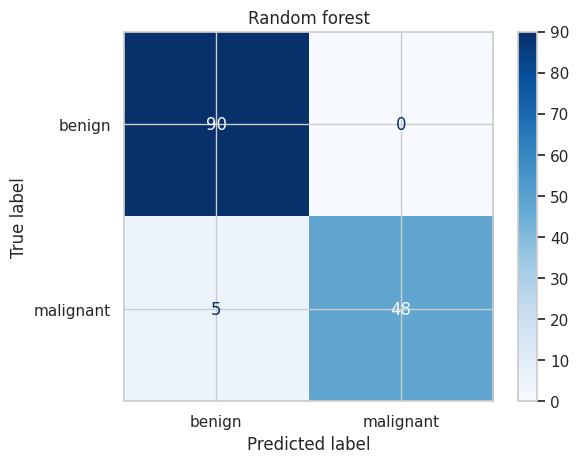

In [17]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
rf = RandomForestClassifier(n_estimators=500, random_state=42)

cv = StratifiedKFold(5, shuffle=True, random_state=42)

for name, model in [("Logistic regression", logreg), ("Random forest", rf)]:
    cv_auc = cross_val_score(model, X_tr, y_tr, cv=cv, scoring="roc_auc")
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]

    print(f"===== {name} =====")
    print(f"5-fold CV AUC (train only): {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}")
    print(f"Test AUC: {roc_auc_score(y_te, proba):.3f}")
    print(classification_report(y_te, pred, target_names=["benign", "malignant"]))

    ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["benign", "malignant"], cmap="Blues")
    plt.title(name)
    plt.show()

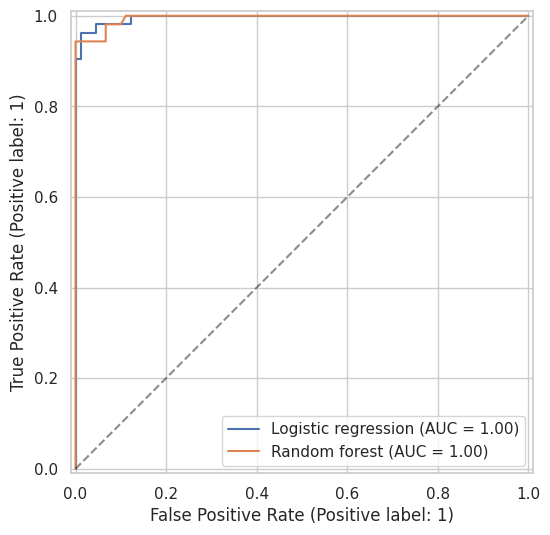

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_estimator(logreg, X_te, y_te, name="Logistic regression", ax=ax)
RocCurveDisplay.from_estimator(rf, X_te, y_te, name="Random forest", ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.show()

In [19]:
coef = pd.Series(logreg.named_steps["logisticregression"].coef_[0], index=features)
rf_imp = pd.Series(rf.feature_importances_, index=features)

perm = permutation_importance(rf, X_te, y_te, n_repeats=30, random_state=42, scoring="roc_auc")
perm_imp = pd.Series(perm.importances_mean, index=features)

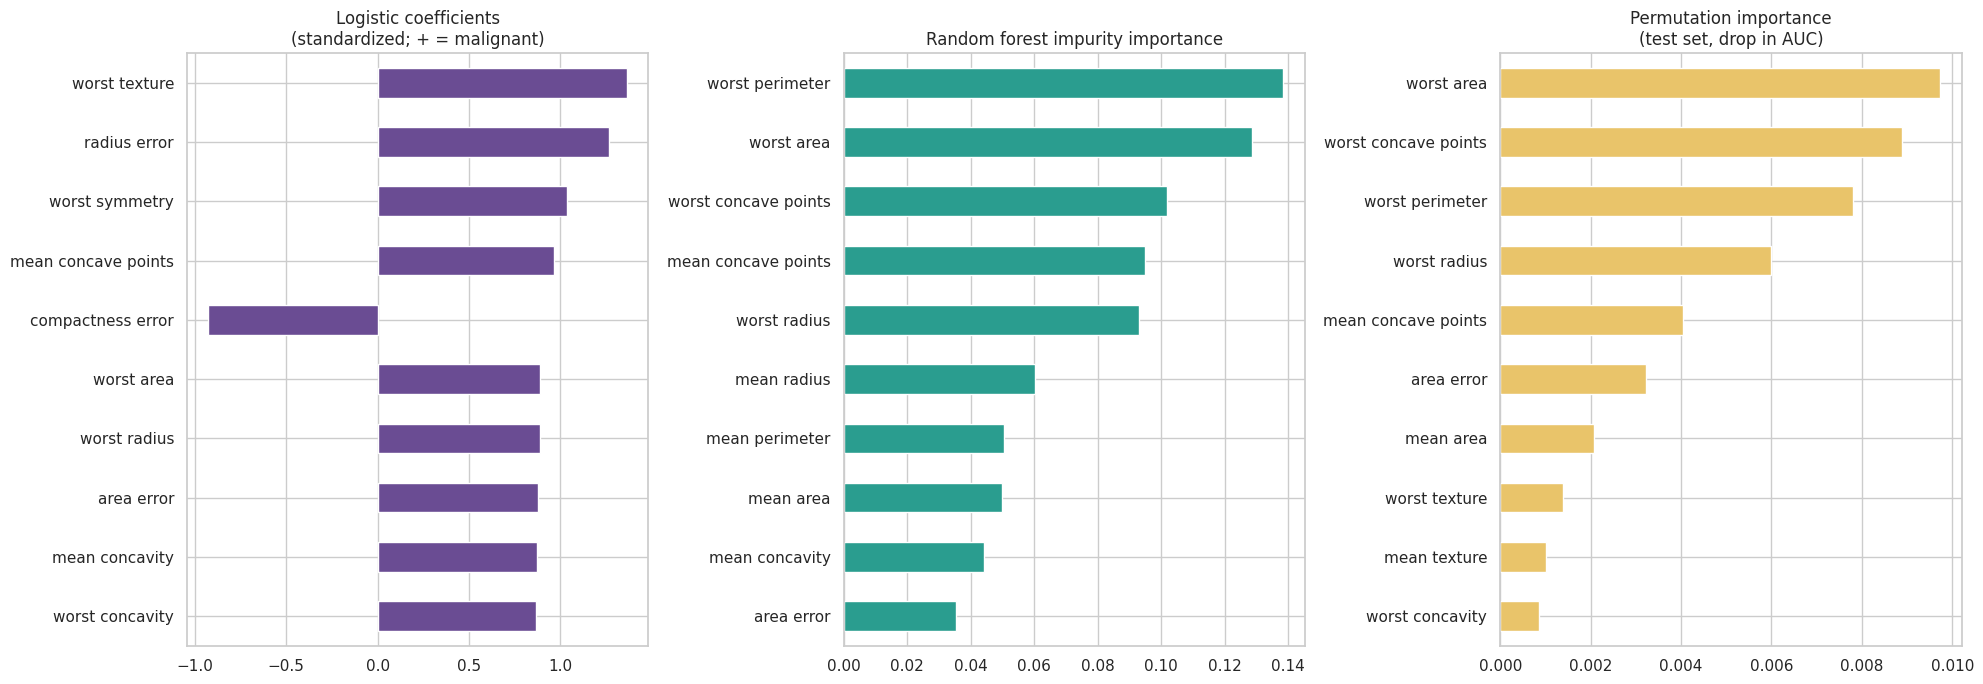

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(20, 7))

coef.reindex(coef.abs().sort_values().tail(10).index).plot.barh(ax=ax[0], color="#6a4c93")
ax[0].set_title("Logistic coefficients\n(standardized; + = malignant)")

rf_imp.sort_values().tail(10).plot.barh(ax=ax[1], color="#2a9d8f")
ax[1].set_title("Random forest impurity importance")

perm_imp.sort_values().tail(10).plot.barh(ax=ax[2], color="#e9c46a")
ax[2].set_title("Permutation importance\n(test set, drop in AUC)")

plt.tight_layout()
plt.show()

In [22]:
corr = X_tr.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
reduced = [f for f in features if f not in to_drop]
print(f"Kept {len(reduced)} of {len(features)} features")

rf_red = RandomForestClassifier(n_estimators=500, random_state=42).fit(X_tr[reduced], y_tr)
print("Reduced-feature test AUC:", roc_auc_score(y_te, rf_red.predict_proba(X_te[reduced])[:, 1]).round(3))

perm_red = permutation_importance(rf_red, X_te[reduced], y_te, n_repeats=30, random_state=42, scoring="roc_auc")
pd.Series(perm_red.importances_mean, index=reduced).sort_values(ascending=False).head(8).round(4)

Kept 20 of 30 features
Reduced-feature test AUC: 0.993


,0
mean radius,0.0356
worst concavity,0.0164
mean concavity,0.0132
radius error,0.0047
mean texture,0.0018
worst compactness,0.0014
symmetry error,0.0010
mean fractal dimension,0.0010
